# Getting started with the `nninterpolator` library

Before starting, we have to make sure that we have previously installed the library inside our local environment with the following terminal command:
>```bash
>pip install local_path/NN-function-interpolator
>```

With `local_path/` being the local directory where we have downloaded the library repository.

## Importing the library

In [1]:
from nninterpolator import Loader, NNInterpolator

Here, `Loader` is the class responsible for reading the input dataset and preparing the data to be processed by the model. `NNInterpolator` is the class that contains all the model routines for its training and later evaluation.

## Loading the data

Before training the model, we need to initialize the `Loader` object that will automatically process and split the dataset for us into a training and a validation group.

In [2]:
load = Loader(trn_perc=0.8, batch_sz=50, shuffle=True, val_batching=False)

- `trn_perc`: percentage of the dataset that will be used in the training process. *It has to be a number between 0 and 1*.

- `batch_sz`: size of the minibatches in which the data will be read by the model during training. Smaller sizes allocate less GPU memory and make the model converge faster to the solution, but more iterations are required for each training epoch. *The default value is `None` (i.e. no minibatching at all)*.

- `shuffle`: controls whether the split and minibatching of the data is done by selecting or not random chunks of data. In this case, given that we are dealing with an interpolation problem, it is very benefitial to shuffle the data so the training set contains points throughout the entire range of the dataset. *The default value is `True` (i.e. random selection is enabled)*.

- `val_batching`: controls whether the validation set is also divided into minibatches of size `batch_sz`. Unnecessary in this case. *The default value is `False` (i.e. no validation minibatching)*.

Now that we have configured our `Loader`, we need to read the file with the dataset that we want to interpolate. Currently, the library is only able to read data in CSV format by using the method `from_csv()`.

In [3]:
dls = load.from_csv(path='../examples/example1a.csv', x_cols=0, y_cols=1)

- `path`: the local path of the file we want to read. In this case we are going to use `example1a.csv` inside the `examples/` folder.

- `x_cols`: the indices od the columns in which the independent variable (i.e. **x**) is stored. It can be both a single **integer** or a **list of integers** if the function is 2D or more.

- `y_cols`: the same as `x_cols` but with the dependent variable (i.e. **y**, the value of the function).

Here, given that [example1a.csv](../examples/example1a.csv) contains a 1D function dataset, we tell the `Loader` that **x** is inside the first column of the dataset and **y** in the second column. As a result of calling `load.from_csv()` we get a tuple containing the training and validation sets as **pytorch** `DataLoader` classes, which manage all the ordering and minibatching of the data so it can be properly inputed to the model.

## Training the model

Now that we have preprocessed the data into the correct format, we can **train** the model. To do so, we first need to initialize the `NNInterpolator` object specifying the main features of the neural network that we want to build. 

In [5]:
model = NNInterpolator(nlay=4, lay_sz=64)

- `nlay`: total number of neuron layers (or *depth*) that form the neural network (i.e. input layer + hidden layers). The more layers the network contains the more complex and flexible it will be, but the training process will be longer.

- `lay_sz`: *width* of each layer (i.e. amount of neurons per layer). Wider layers can reproduce finer features.

Once the network architecture is defined, we can call the `fit()` method to train the model with the processed dataset `dls` that we got before. 

In [ ]:
history = model.fit(dls=dls, lr=0.1, nepochs=1000, plot=False)

- `dls`: dataset containing both the training and validation set in **pytorch** `DataLoader` format.

- `lr`: learning rate used to update the network coefficients during training. It needs to be fine-tuned so that it is small enough to guarantee that the training process converges and big enough to avoid training too slowly. *The default value is `lr=1e-3`*.

- `nepochs`: number of epochs (or *iterations*) of the training process. More epochs let to better fits as long as the training process is convergent with the `lr` picked. *The default value is `nepochs=10`*.

- `plot`: controls whether the loss function and the final fit are plotted in graphs at the end of the training. *The default value is `False`.

Here we set `lr=0.1` and train the model for 1000 epochs as it gives a pretty good result at a low time cost. As a result, `fit()` returns a dictionary `history` of two lists with the evolution of both the training and the validation loss (computed with the **MSE**) at each epoch. We can always inspect this *training history* as follows:

In [9]:
history = model.history
print(f'train loss: {history['train_loss'][0]}, ..., {history['train_loss'][-1]}')
print(f'validation loss: {history['val_loss'][0]}, ..., {history['val_loss'][-1]}')

train loss: 1.3242339068923255, ..., 0.09212503109235487
validation loss: 1.7394483089447021, ..., 0.19266685843467712


We can also inspect the values of the network coefficients after training:

In [18]:
weights, biasses = model.coeffs()
print(f'Input layer weights: {weights[0]}')
print(f'Input layer biasses: {biasses[0]}')

Input layer weights: tensor([[ 3.4673,  0.3482,  0.5253,  0.1946,  1.3368, -1.0153, -0.9163, -0.4518,
          0.3639, -0.1606, -2.1880, -1.1510,  0.1918,  0.2179, -0.7888, -1.2647,
         -1.6339, -0.8995, -3.2748, -0.4923,  1.4658,  0.8286, -0.9094,  0.3047,
          0.2308,  1.3699, -0.4490, -0.3281,  0.2271, -1.1354,  2.8705, -0.2644,
         -0.6322, -1.0263, -2.3891, -1.4745,  0.1897,  0.5017, -2.6013,  1.0849,
          0.7977, -2.5224,  2.1444, -1.6456, -0.3285,  1.0031,  1.2291, -1.0524,
         -1.1199, -1.5547,  0.5741, -0.2312, -0.4339,  1.6200, -0.2208,  0.0514,
         -3.0097, -1.6208, -0.7408,  0.9137, -0.0382, -1.4313, -2.1806, -2.1434]],
       requires_grad=True)
Input layer biasses: tensor([-0.1492,  0.0218,  0.1454, -0.0165, -0.1110, -0.0556,  0.0070,  0.0576,
         0.3121,  0.1447, -0.1517,  0.0989, -0.0269, -0.1503,  0.4779,  0.4739,
         0.1382, -0.3930, -0.3888, -0.0281, -0.1199, -0.0689, -0.0506, -0.0259,
        -0.0190, -0.0227,  0.0981,  0.028

If we now include the final plots (i.e. `plot=True`):

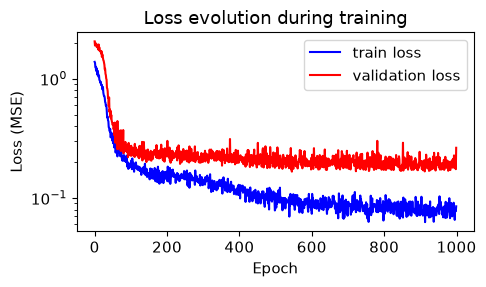

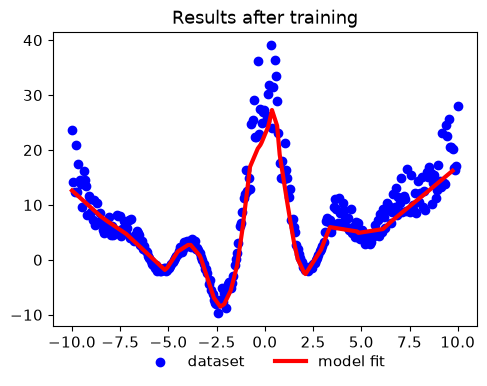

In [10]:
history = model.fit(dls=dls, lr=0.1, nepochs=1000, plot=True)

We can see that this simple NN model can give rad¡ther good results with little effort.

## Evaluating the model

Now that the model has been trained with our dataset, we literally have an continuous function to which we can input desired values of the independent variable and it returns the most approximate outputs to our original dataset, so we can fill all the gaps we had in our data and predict any value **as long as it is contained within the original data's range**. As it clearly won't be able to predict outputs outside the trained range (i.e. it will not perform any **extrapolation**). *You can see a detailed example of this in [model_tuning_deep-dive.ipynb](./model_tuning_deep-dive.ipynb)*.

Given that the example dataset was obtained from a random perturbation of a known analytical function, we can see how closely has the model fitted to it.

In [11]:
import torch
import matplotlib.pyplot as plt

In [12]:
def real_func(x):
    return  2*torch.tanh(x) + 10*torch.sin(2*x)/x + x**4/1000 + torch.cosh(x/5)

To compare both series we need to define a test sequence of x values and evaluate both the trained model (with the `predict()` method) and the real function.

In [19]:
x_test = torch.linspace(-10, 10, 500)

preds = model.predict(x_test)
y_real = real_func(x_test)

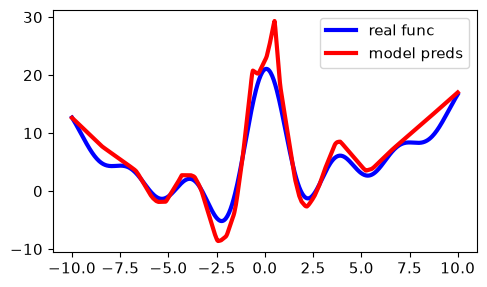

In [20]:
fig, ax = plt.subplots(figsize=(5,3))
ax.plot(x_test, y_real, c='blue', lw=3, label='real func')
ax.plot(x_test, preds, c='red', lw=3, label='model preds')
plt.legend()
plt.tight_layout()
plt.show()

This figure shows that our simple fit is not that far off!

## 2D case

For the sake of completeness, we can also show what would be the workflow for a 2D dataset (i.e. **f(x,y)**). Simply, the only think that will need to be changed is the inputs of the `from_csv()` method, so that now `x_cols` will be a list of two indices instead of a single integer. The model automatically manages the rest.

In [21]:
dls = Loader(trn_perc=0.8, batch_sz=50).from_csv('../examples/example2.csv', x_cols=[0,1], y_cols=2)

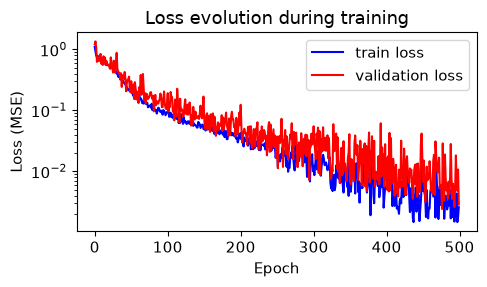

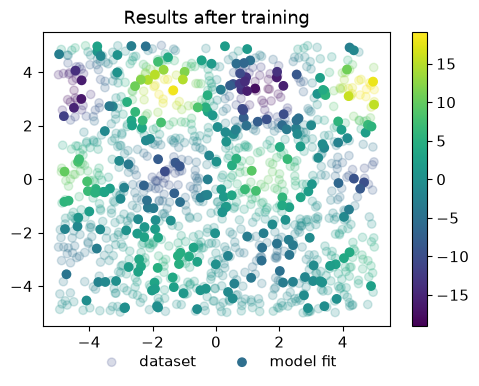

In [23]:
history = NNInterpolator(nlay=4, lay_sz=64).fit(dls, lr=0.1, nepochs=500, plot=True)

As we can see, the model still performs completely fine. So technically it can fit any **N-dimensional** dataset. However, the plotting option will be disabled for more than 2D.